# Extra Trees (Extremely Randomized Trees) — Milestone M6b

**Model**: `ExtraTrees` (`extra_trees`)  
**Milestone**: M6b — Classic Machine Learning Models  
**Evaluated Problems**:
- **S1**: Pavagada Solar Generation (1-hour ahead)
- **S24**: Pavagada Solar Generation (24-hours ahead / Day-Ahead)
- **D1**: Karnataka Grid Demand (1-hour ahead)
- **D24**: Karnataka Grid Demand (24-hours ahead / Day-Ahead)

### Purpose & Theoretical Description
Randomized ensemble of decision trees that draws cut-points completely at random for each candidate feature. Offers even greater variance reduction and computational speed than standard Random Forest.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Ensure project root is accessible from models/classic_ml/
project_root = Path.cwd().parent.parent if Path.cwd().name == "classic_ml" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import config
import src.models_ml as mml

print("Project root successfully linked:", project_root)


Project root successfully linked: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT


## 1. Load M4 Processed Datasets & Train Model
In strict compliance with roadmap rules:
- Data is loaded directly from `data/processed/` without modifying features or preprocessing.
- Training set: `2021-03-08` → `2024-12-31`
- Validation set: `2025-01-01` → `2025-12-31`
- Test set: `2026-01-01` → `2026-02-28` (**Quarantined - Never used for training or model selection**)


In [2]:
model_name = "extra_trees"
model_kwargs = {'n_estimators': 100, 'max_depth': 15}
problems = ["S1", "S24", "D1", "D24"]

results = []
for pid in problems:
    res = mml.train_and_eval_ml_model(
        model_name=model_name,
        problem_id=pid,
        model_kwargs=model_kwargs,
    )
    # Generate and save diagnostic figures
    saved_figs = mml.plot_ml_diagnostics(res)
    results.append(res)


LOADING PROCESSED DATASET FOR PROBLEM: S1
Target: solar_power_mw | Horizon: 1h
Using Scaled Features: False
• Training Features Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_train_S1.parquet
• Training Target Path:     C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_train_S1.parquet
• Validation Features Path: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_val_S1.parquet
• Validation Target Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_val_S1.parquet
• Test Features Path:       C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_test_S1.parquet (QUARANTINED - NOT TOUCHED)

Training EXTRA_TREES on S1 (44 features, 33480 rows)...


Saved model artifact: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\models\extra_trees_S1.joblib


C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\src\models_ml.py:329: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="importance", y="feature", data=imp_df, palette="viridis")


LOADING PROCESSED DATASET FOR PROBLEM: S24
Target: solar_power_mw | Horizon: 24h
Using Scaled Features: False
• Training Features Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_train_S24.parquet
• Training Target Path:     C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_train_S24.parquet
• Validation Features Path: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_val_S24.parquet
• Validation Target Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_val_S24.parquet
• Test Features Path:       C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_test_S24.parquet (QUARANTINED - NOT TOUCHED)

Training EXTRA_TREES on S24 (41 features, 33480 rows)...


Saved model artifact: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\models\extra_trees_S24.joblib


C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\src\models_ml.py:329: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="importance", y="feature", data=imp_df, palette="viridis")


... (2 outputs left out)

C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\src\models_ml.py:329: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="importance", y="feature", data=imp_df, palette="viridis")


LOADING PROCESSED DATASET FOR PROBLEM: D24
Target: demand_mw | Horizon: 24h
Using Scaled Features: False
• Training Features Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_train_D24.parquet
• Training Target Path:     C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_train_D24.parquet
• Validation Features Path: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_val_D24.parquet
• Validation Target Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_val_D24.parquet
• Test Features Path:       C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_test_D24.parquet (QUARANTINED - NOT TOUCHED)

Training EXTRA_TREES on D24 (41 features, 33480 rows)...


Saved model artifact: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\models\extra_trees_D24.joblib


C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\src\models_ml.py:329: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="importance", y="feature", data=imp_df, palette="viridis")


## 2. Validation Metrics & Performance Benchmark
Evaluation across all 8 roadmap metrics:
1. **RMSE** (Root Mean Squared Error, MW)
2. **MAE** (Mean Absolute Error, MW)
3. **nMAE** (Normalized MAE, % of 2,050 MW capacity for solar, % of mean for demand)
4. **MAPE** (Demand only, %; omitted for solar to prevent zero division)
5. **sMAPE** (Symmetric MAPE, %)
6. **R²** (Coefficient of Determination)
7. **MBE** (Mean Bias Error, MW)
8. **Skill Score vs Persistence** (% improvement over Milestone M5 baseline floor)


In [3]:
metrics_df = mml.save_and_record_ml_results(results, model_name)
display(metrics_df)



Saved validation predictions to: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\predictions\extra_trees_val_predictions.parquet
Saved validation metrics table to: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\tables\extra_trees_val_metrics.csv


,model,problem,target,horizon,rmse,mae,nmae_pct,mape_pct,smape_pct,r2,mbe,skill_vs_persistence,daylight_rmse,daylight_mae,daylight_nmae_pct
0,extra_trees,S1,solar_power_mw,1h,45.34,11.96,0.58,NaN,2.84,0.9938,6.79,78.52,63.88,23.75,1.16
1,extra_trees,S24,solar_power_mw,24h,49.03,12.32,0.60,NaN,2.92,0.9928,6.60,76.90,69.07,24.45,1.19
2,extra_trees,D1,demand_mw,1h,249.17,179.52,1.43,1.43,1.44,0.9861,-58.40,62.81,NaN,NaN,NaN
3,extra_trees,D24,demand_mw,24h,496.37,382.22,3.04,2.99,3.02,0.9447,-192.58,35.64,NaN,NaN,NaN


## 3. Diagnostic Visualizations
Inspection of prediction tracking, residual distributions, and feature importance rankings.



DIAGNOSTIC PLOTS FOR PROBLEM S1


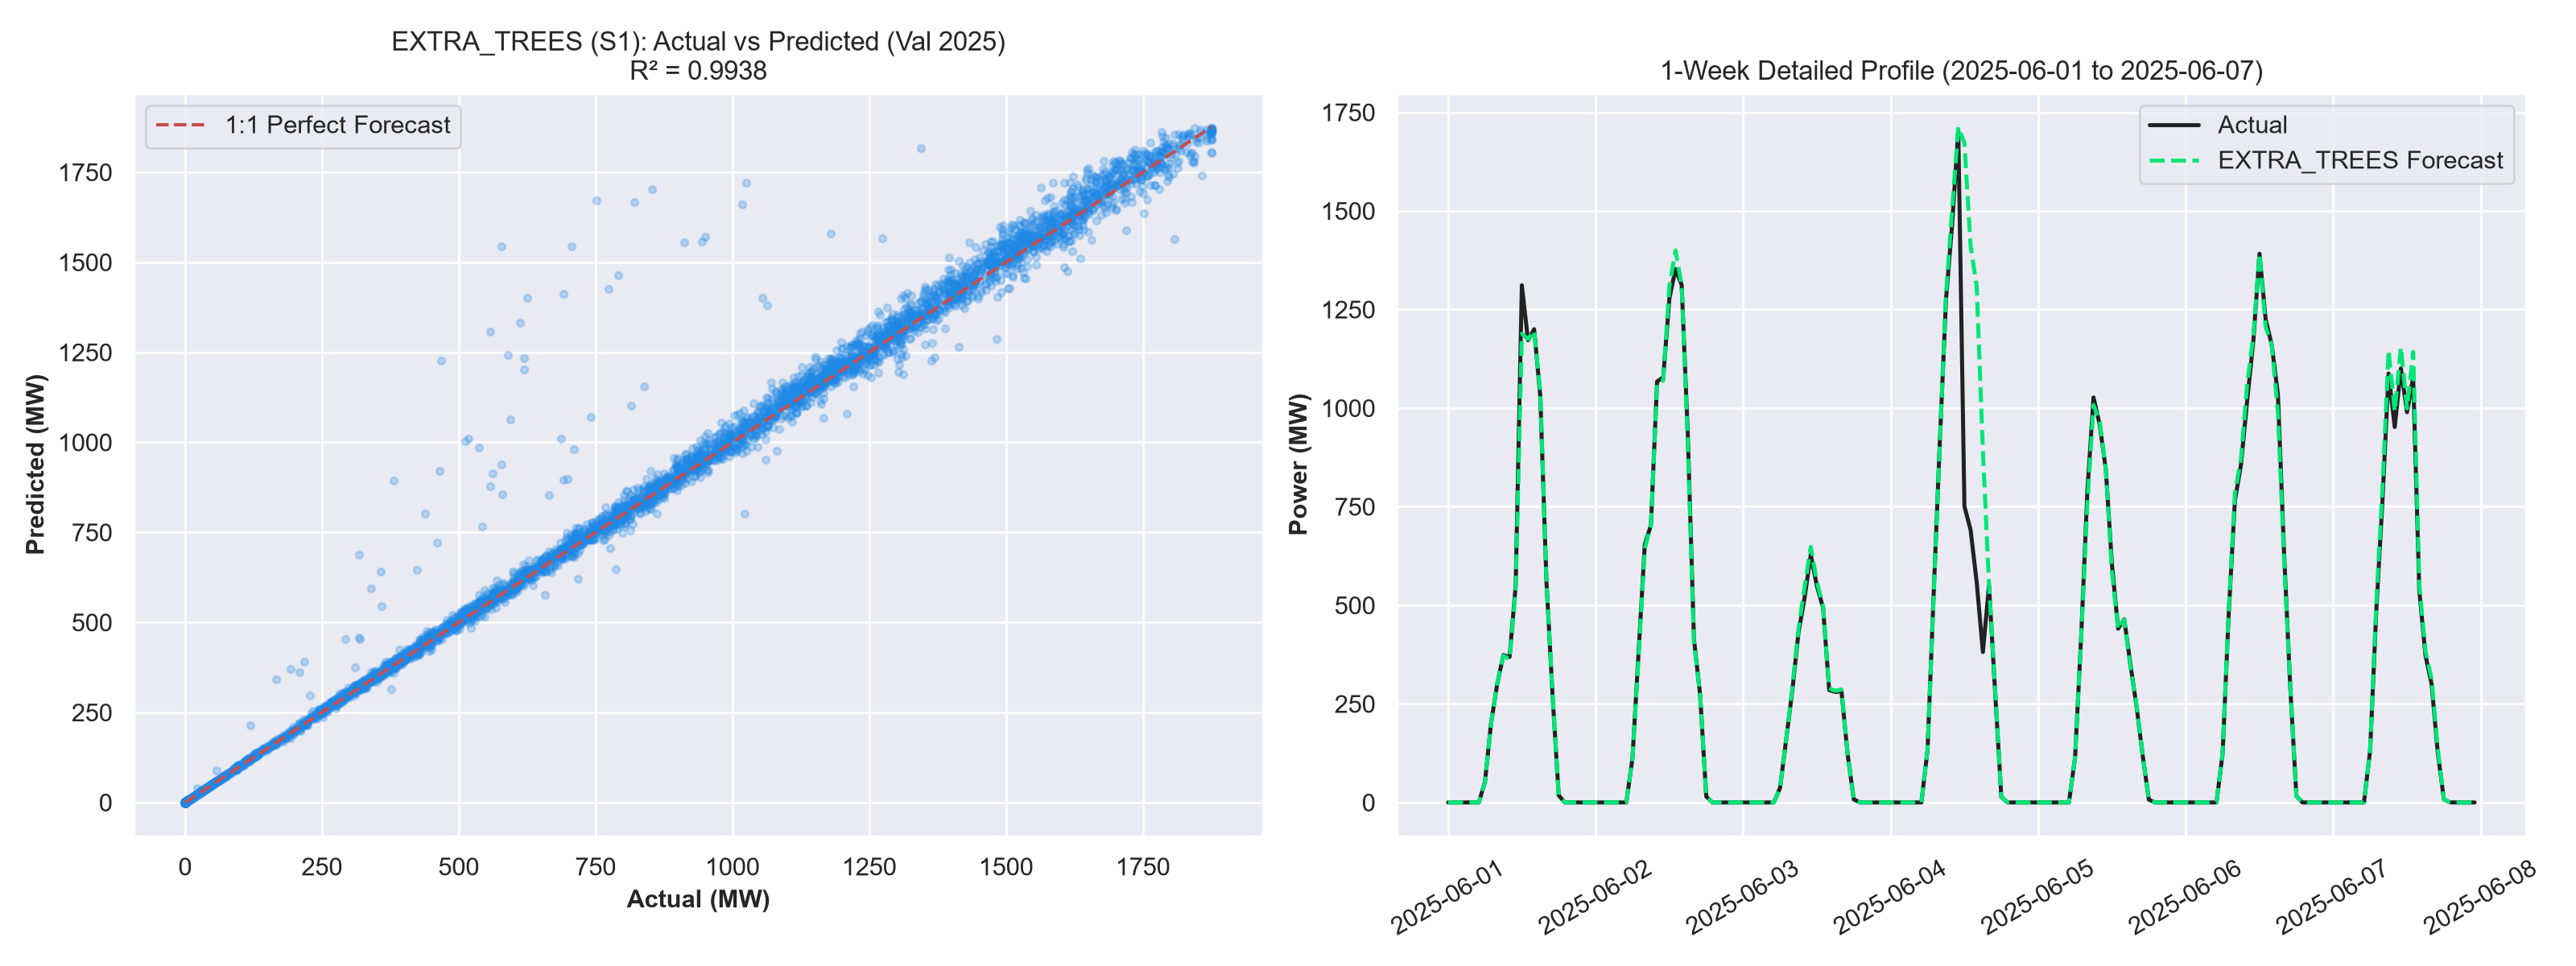

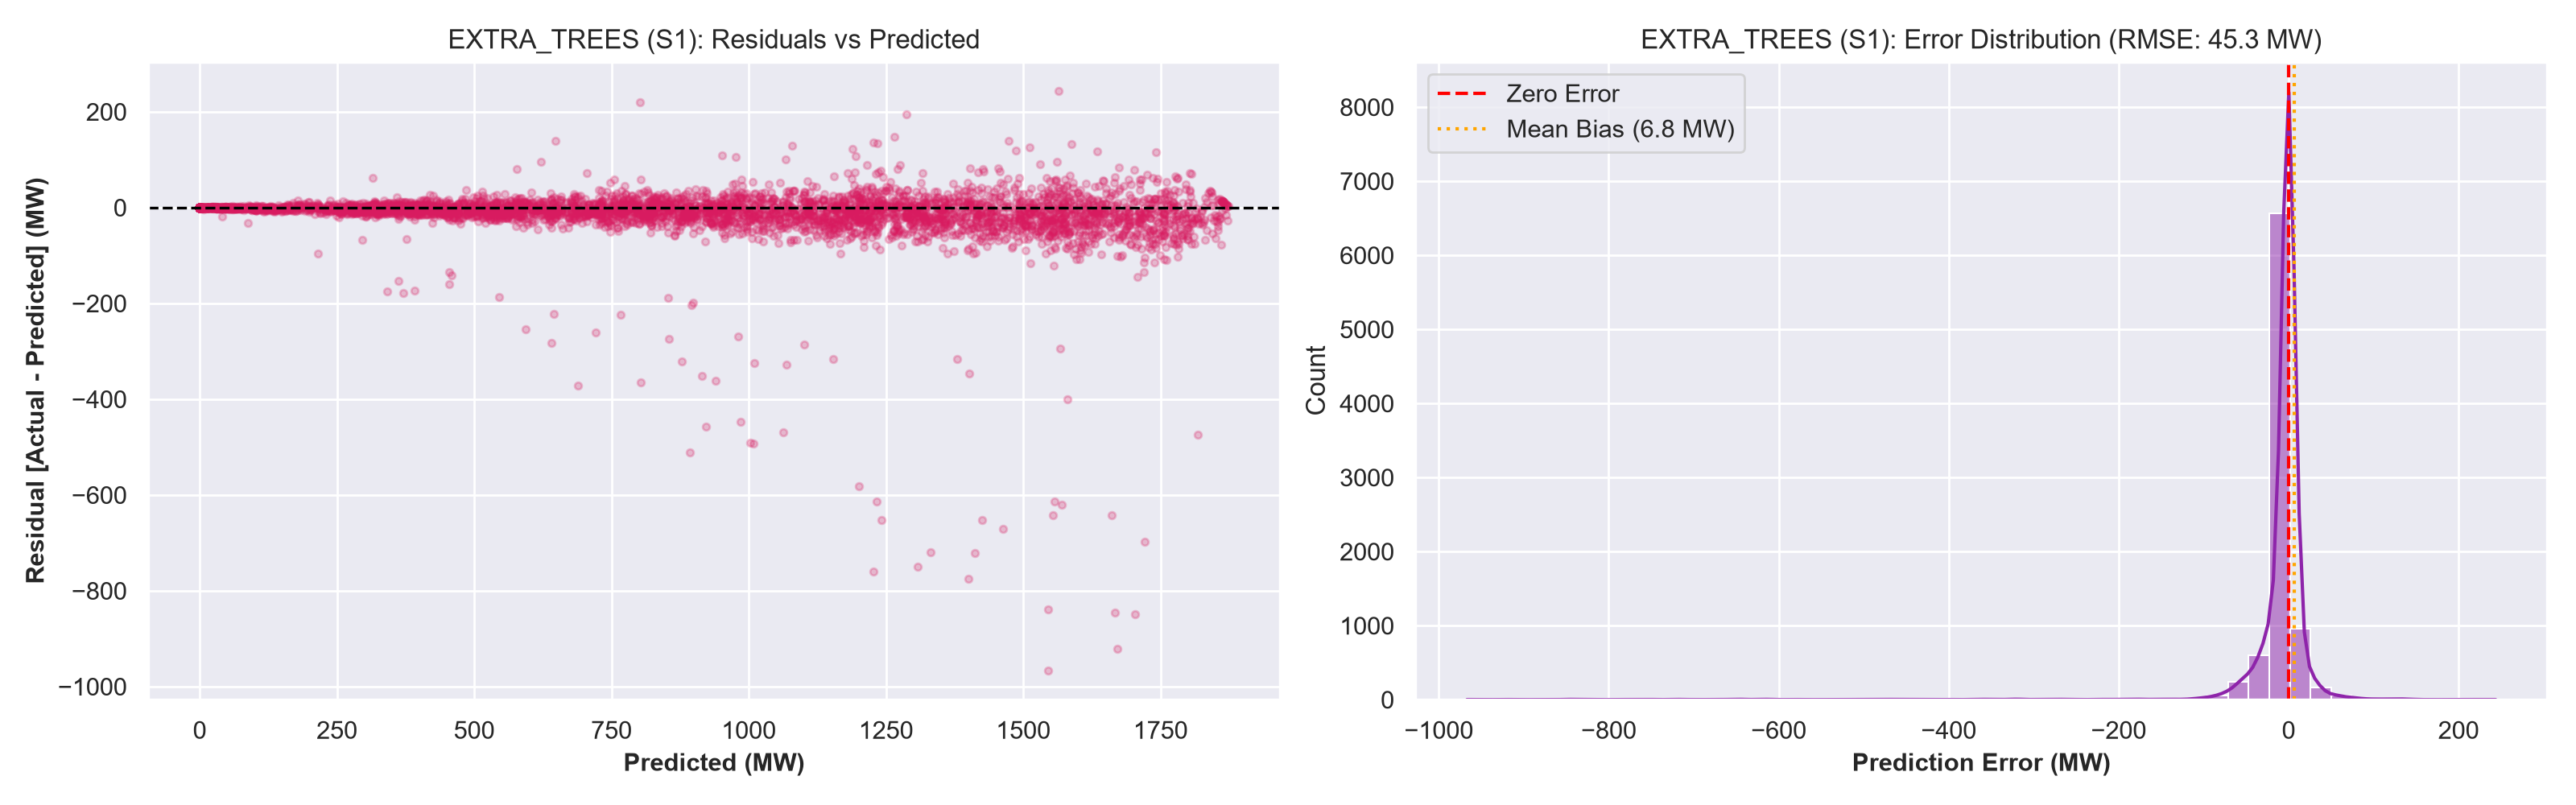

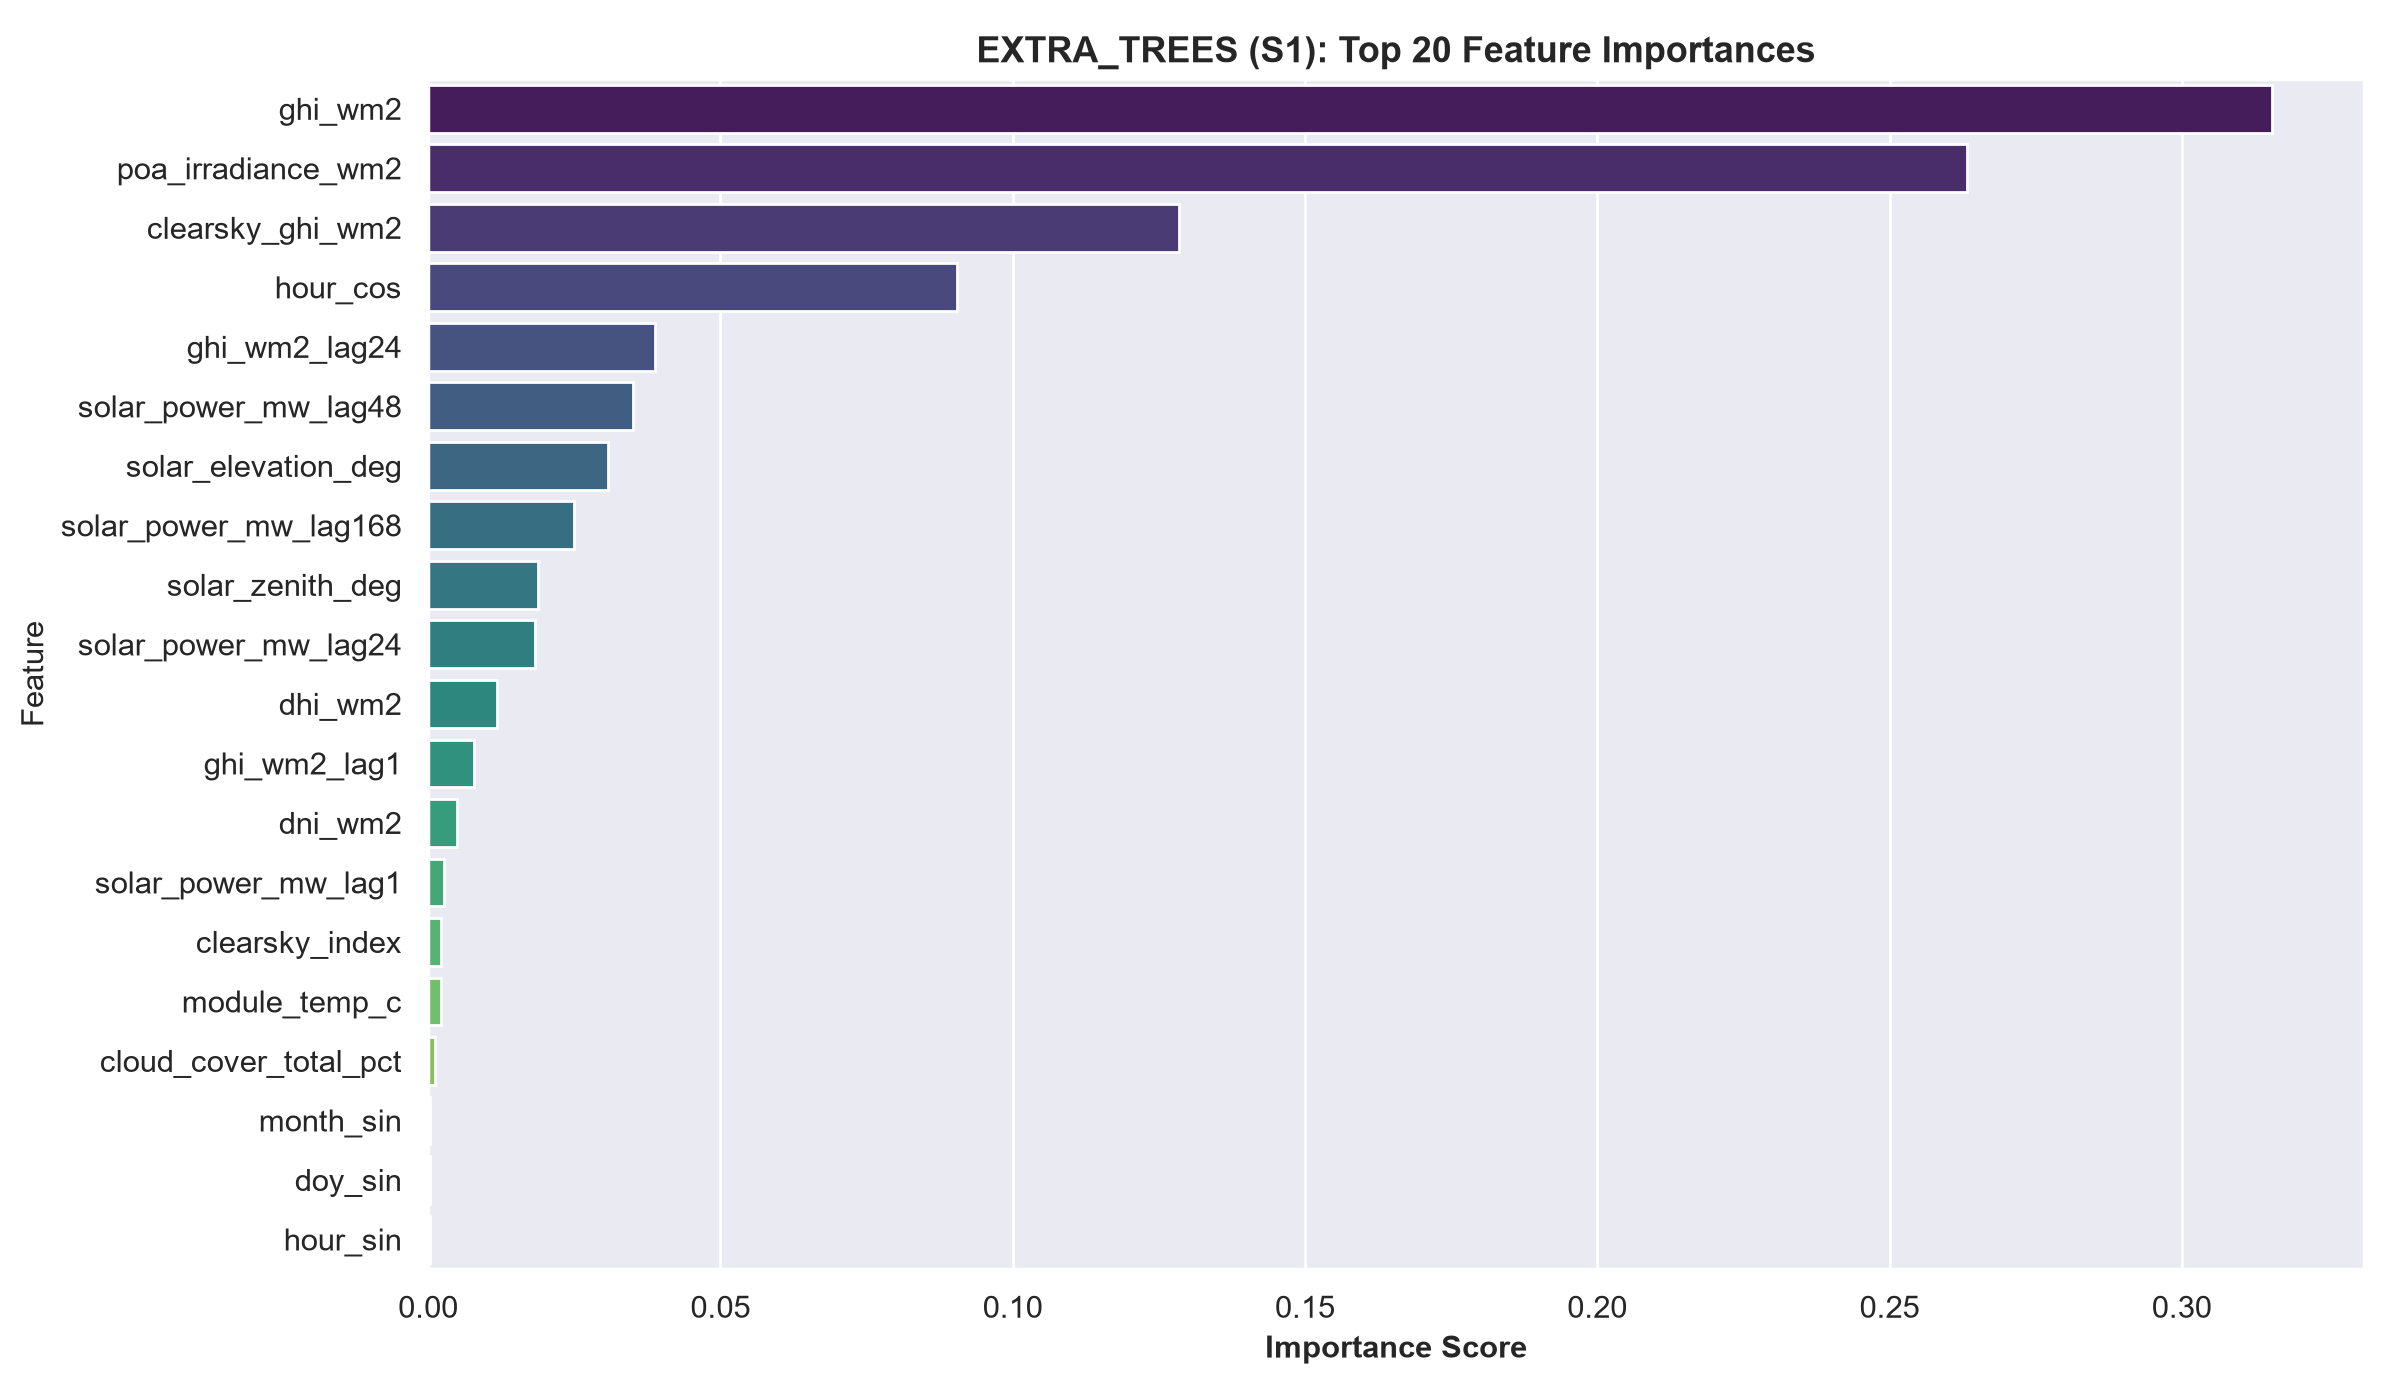


DIAGNOSTIC PLOTS FOR PROBLEM S24


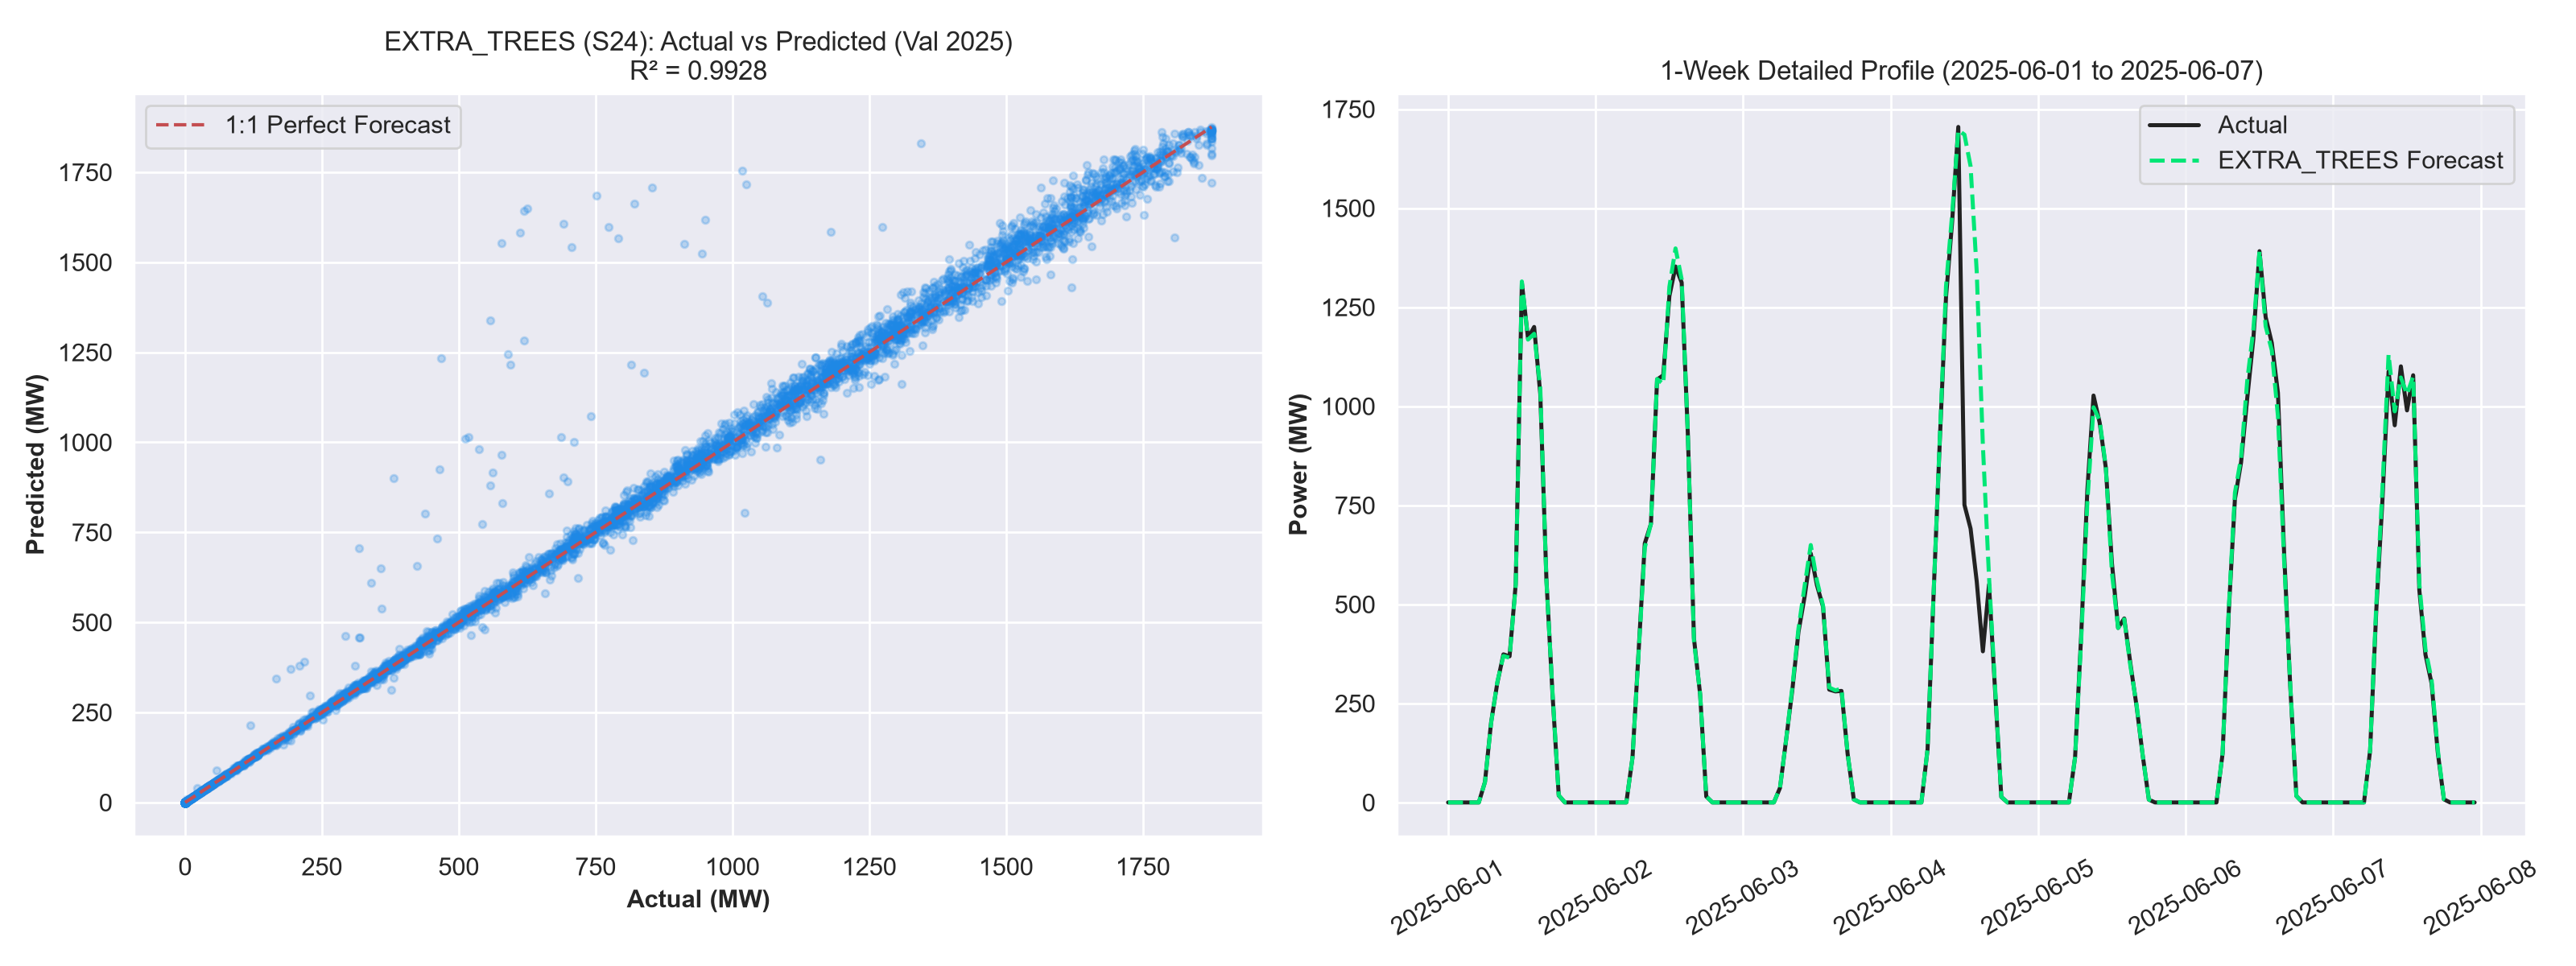

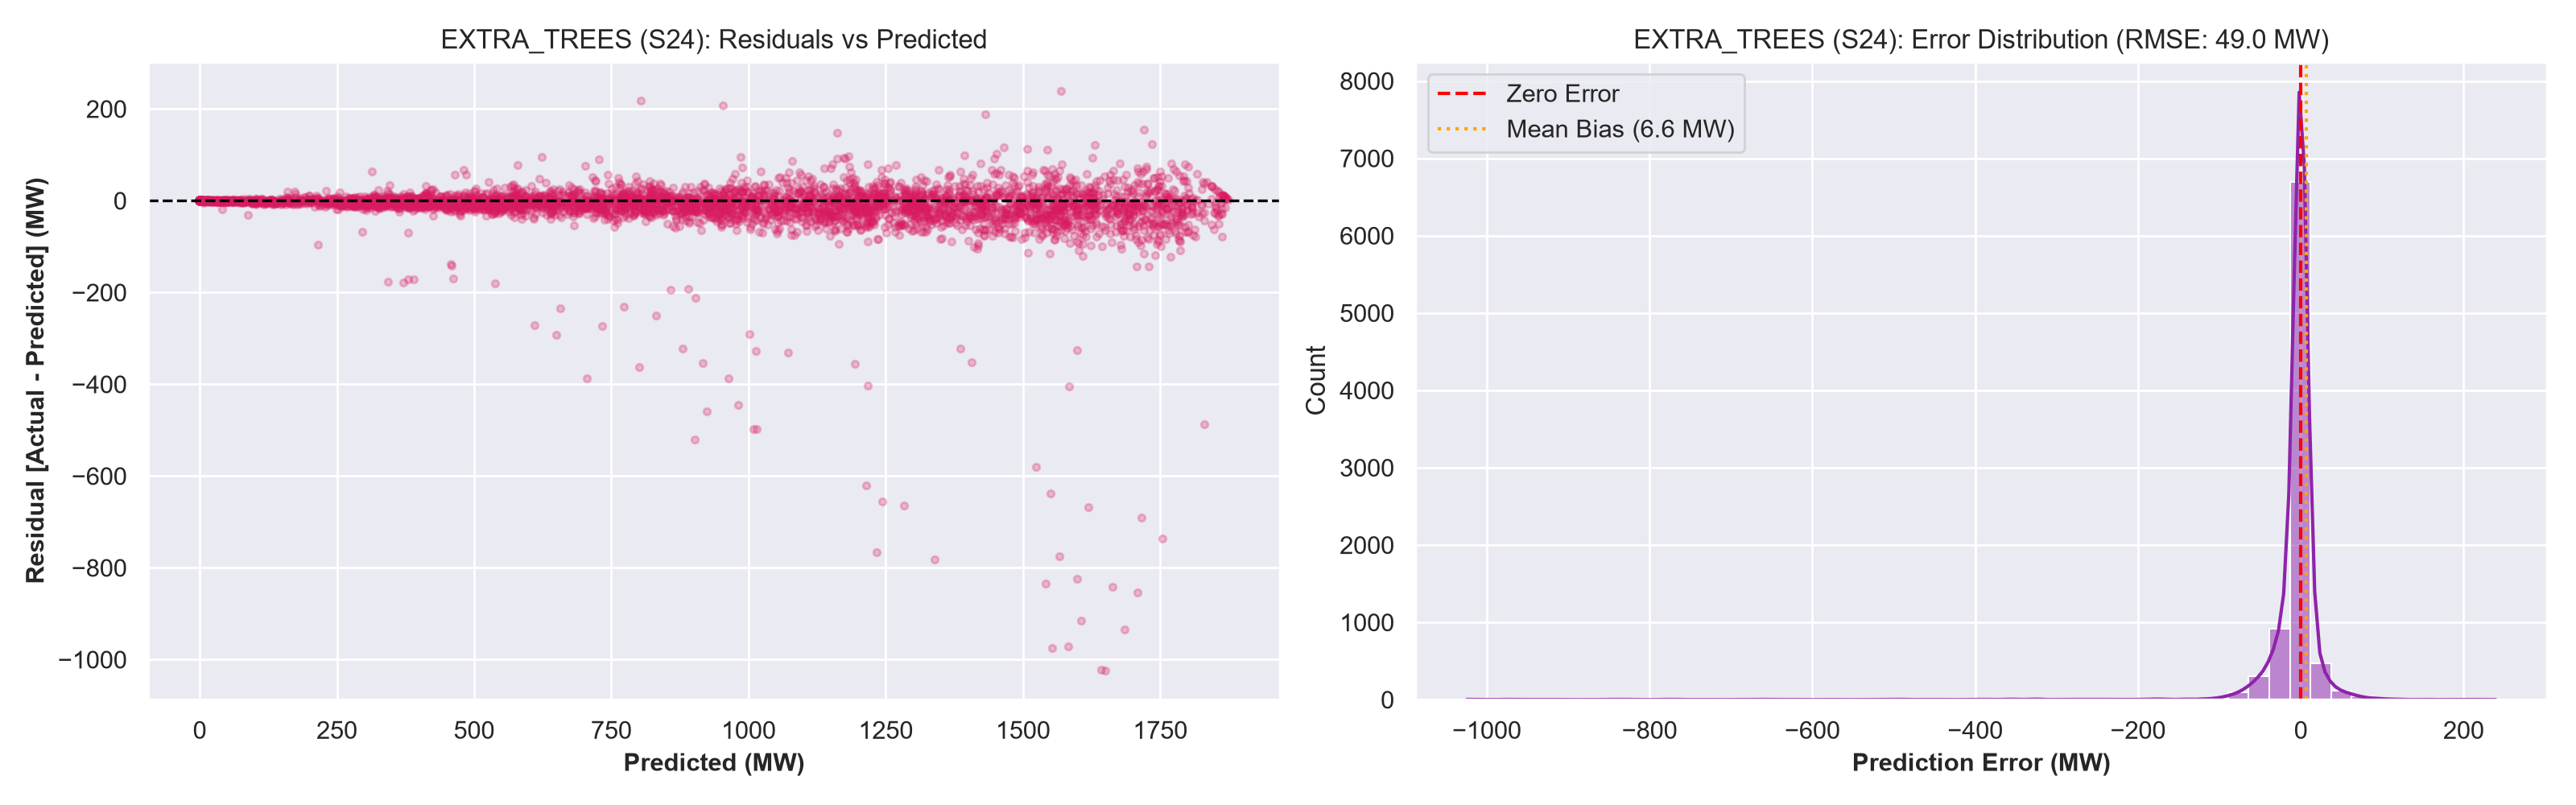

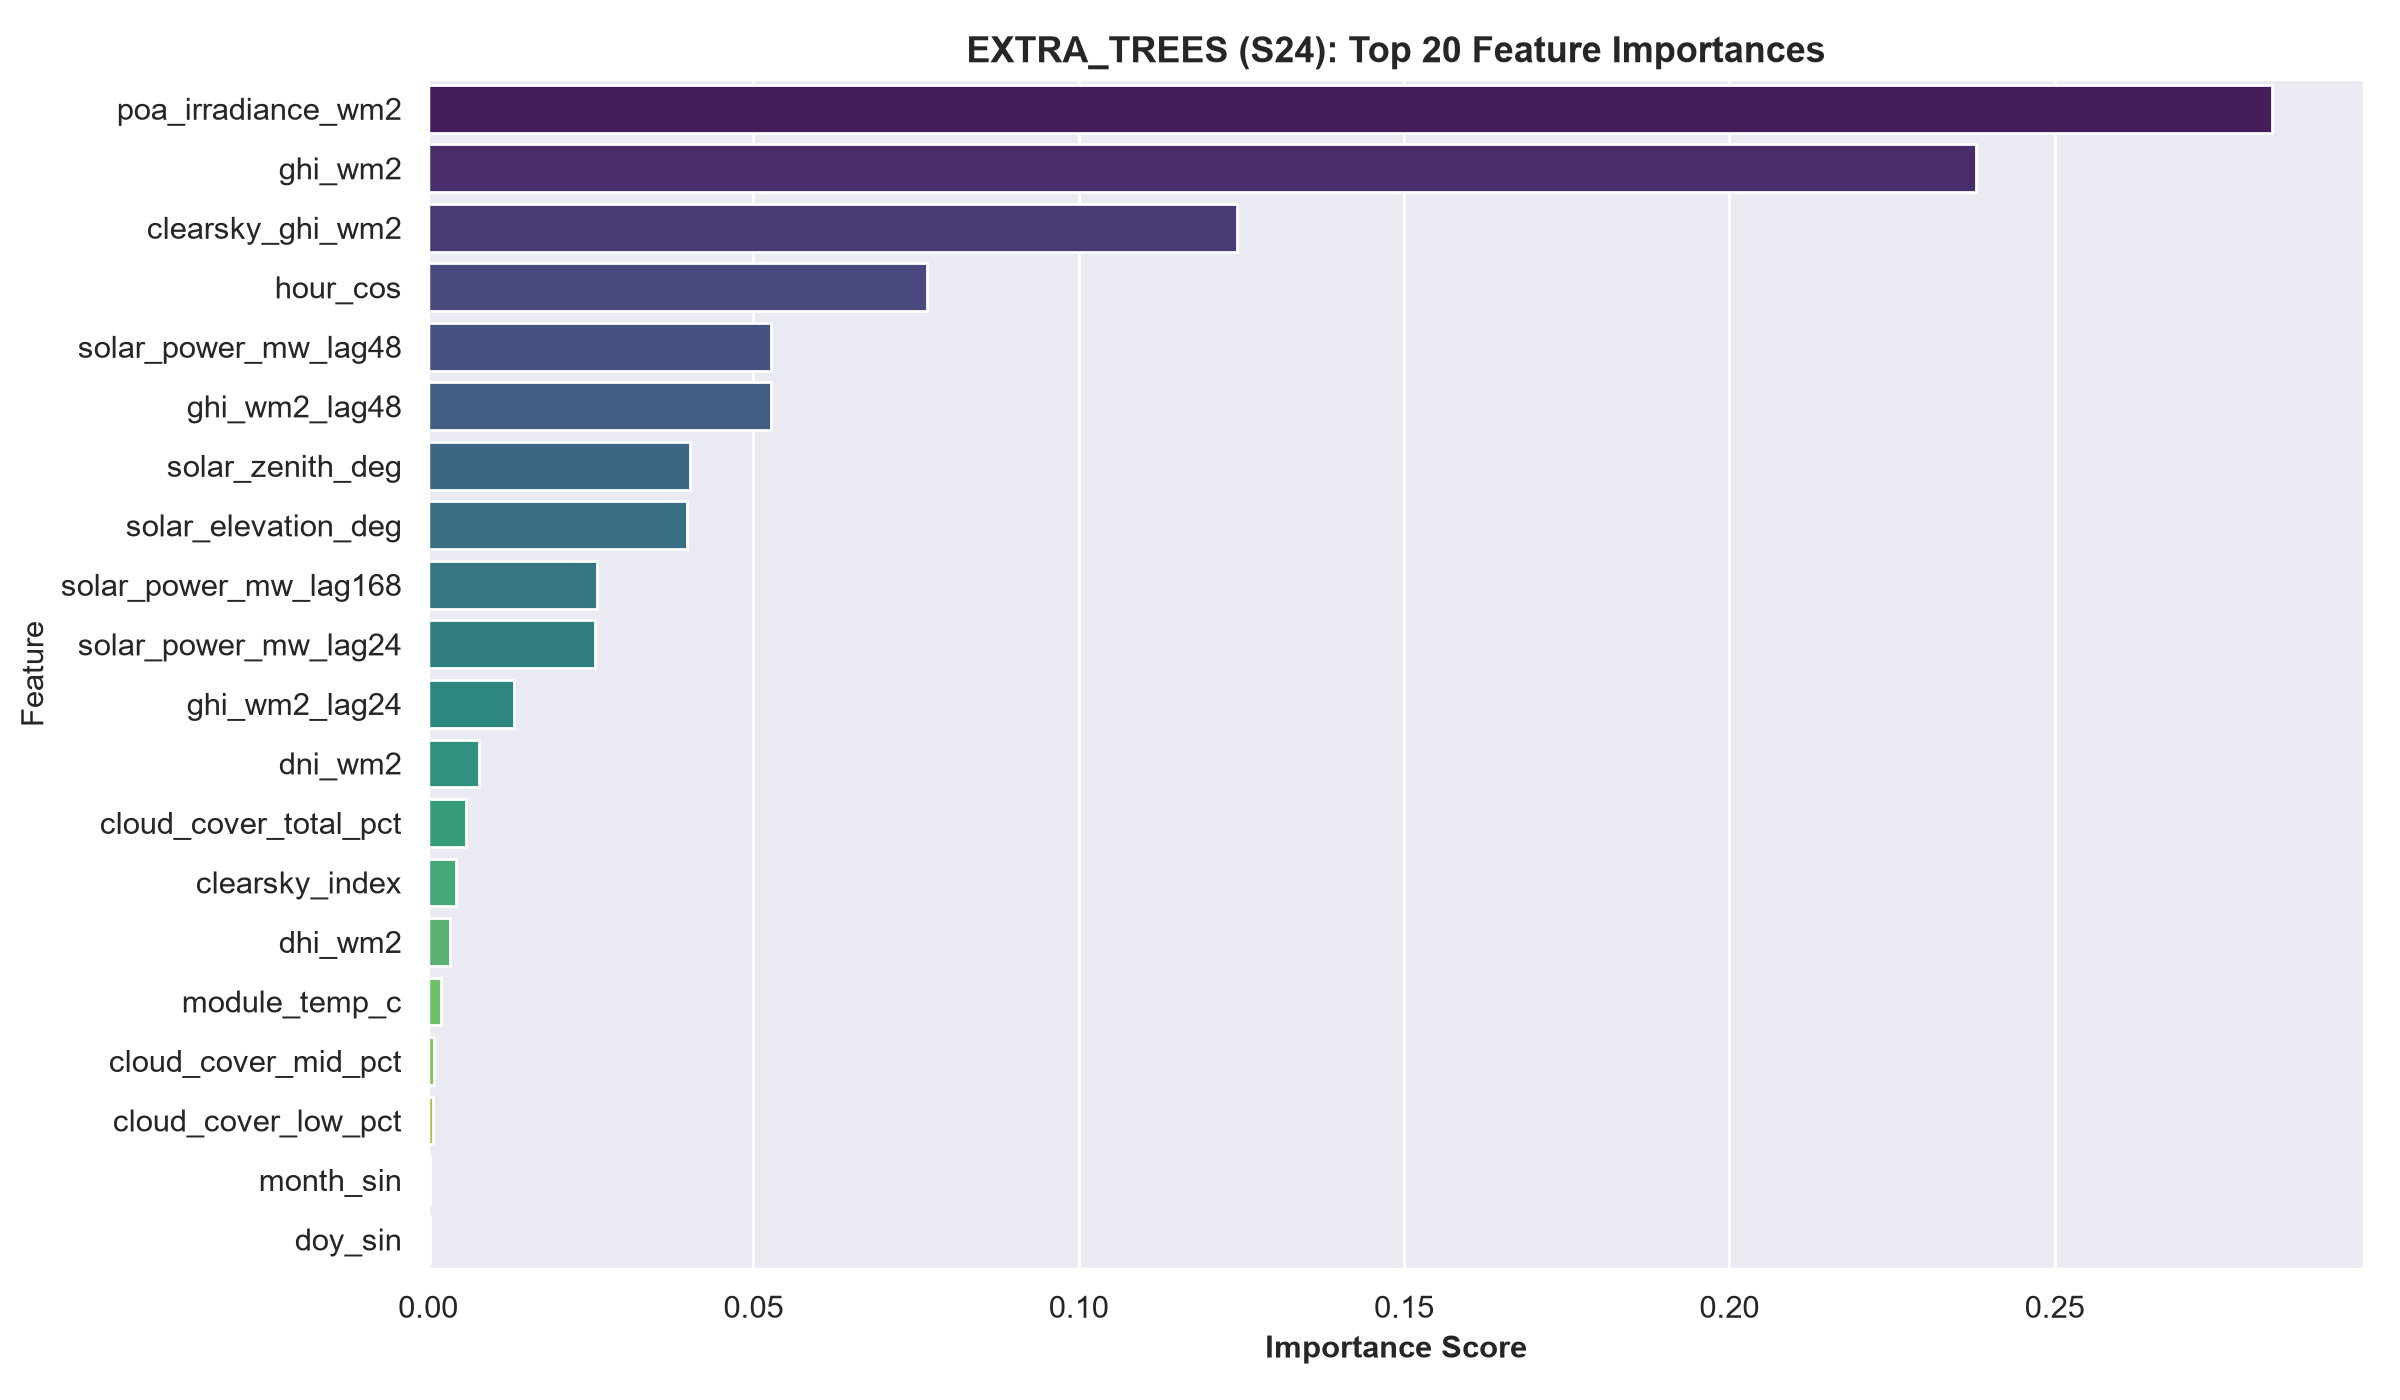


DIAGNOSTIC PLOTS FOR PROBLEM D1


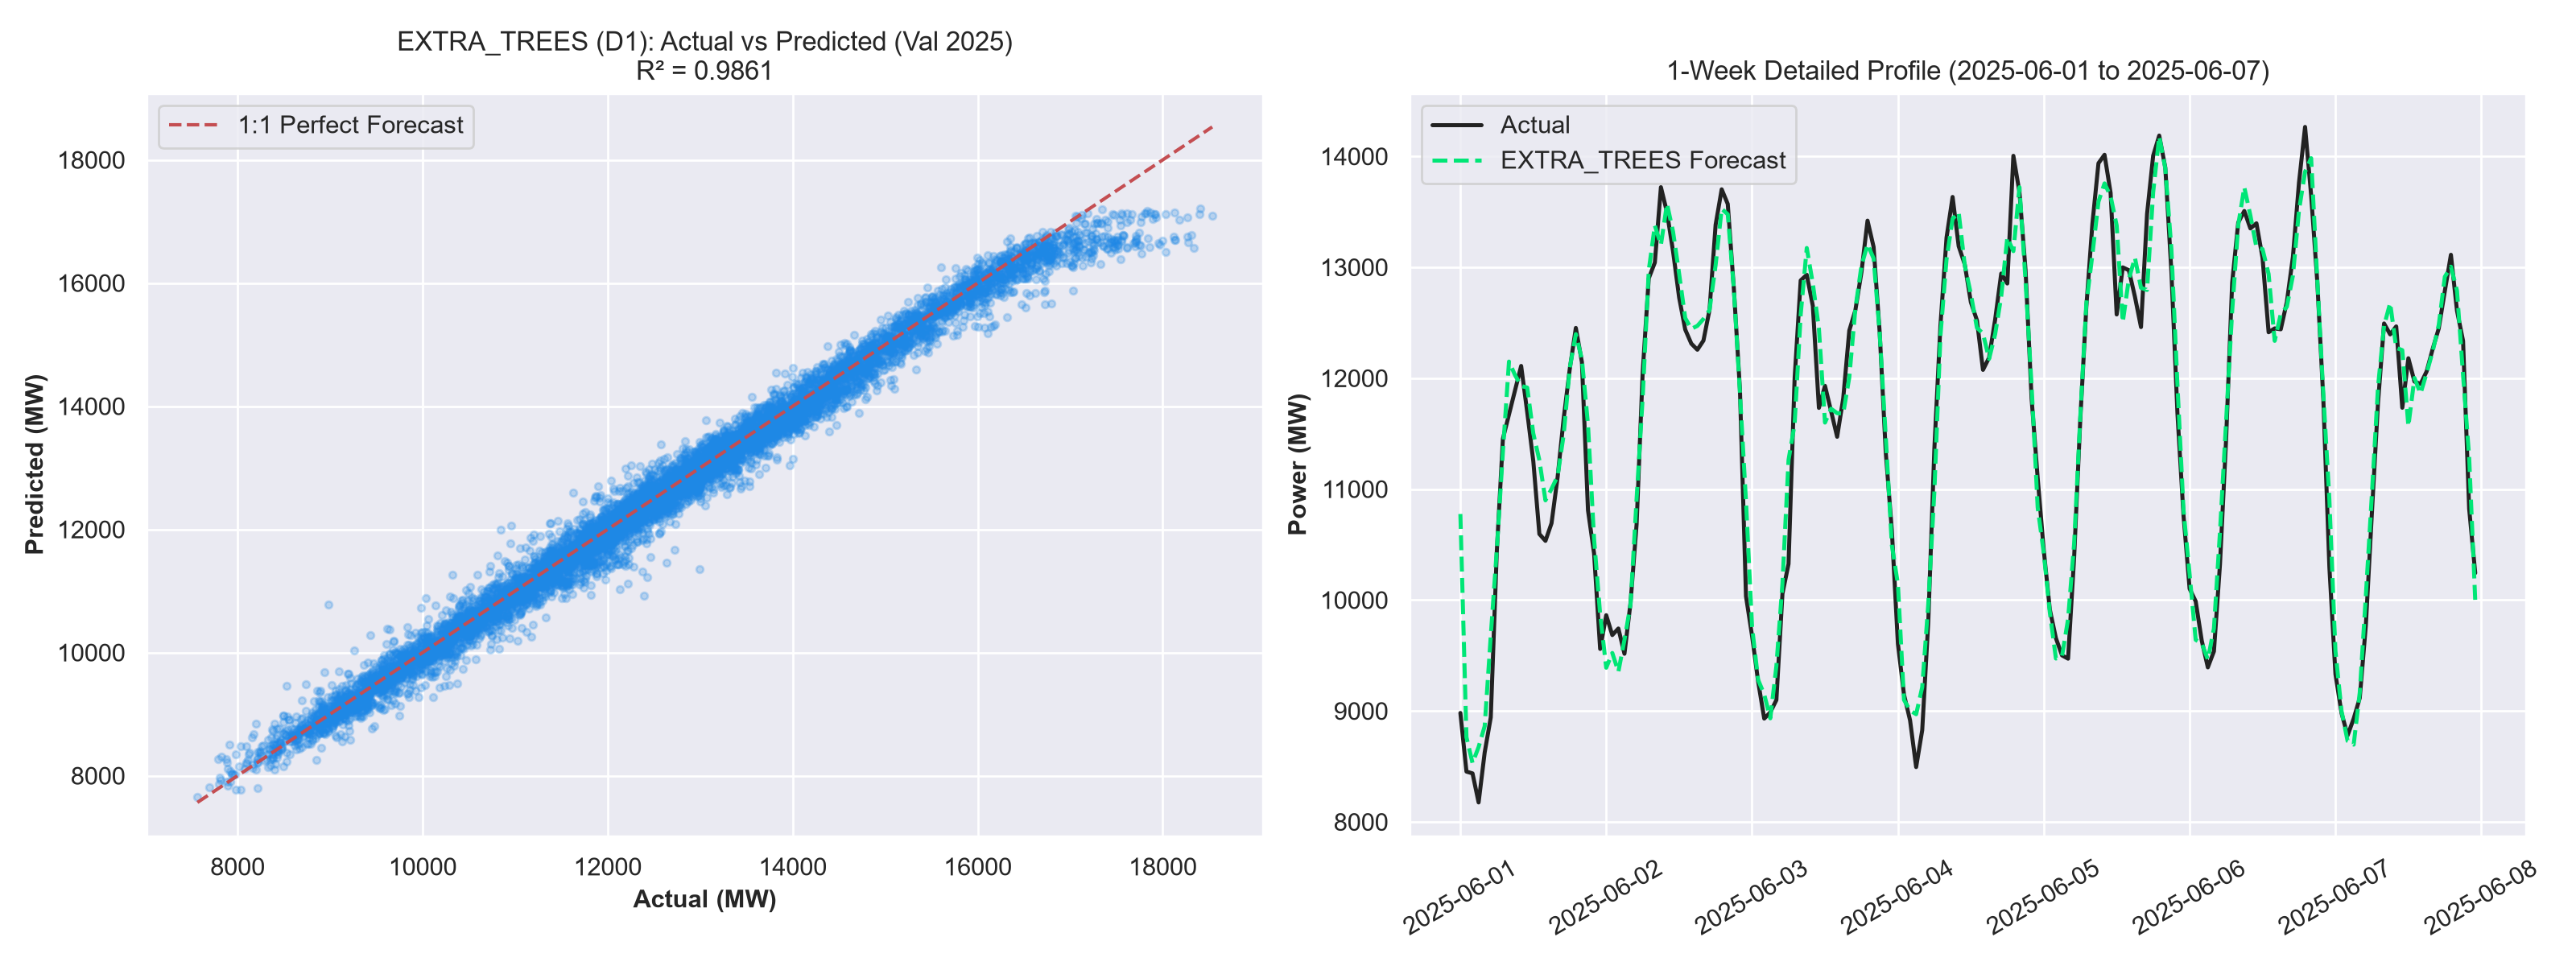

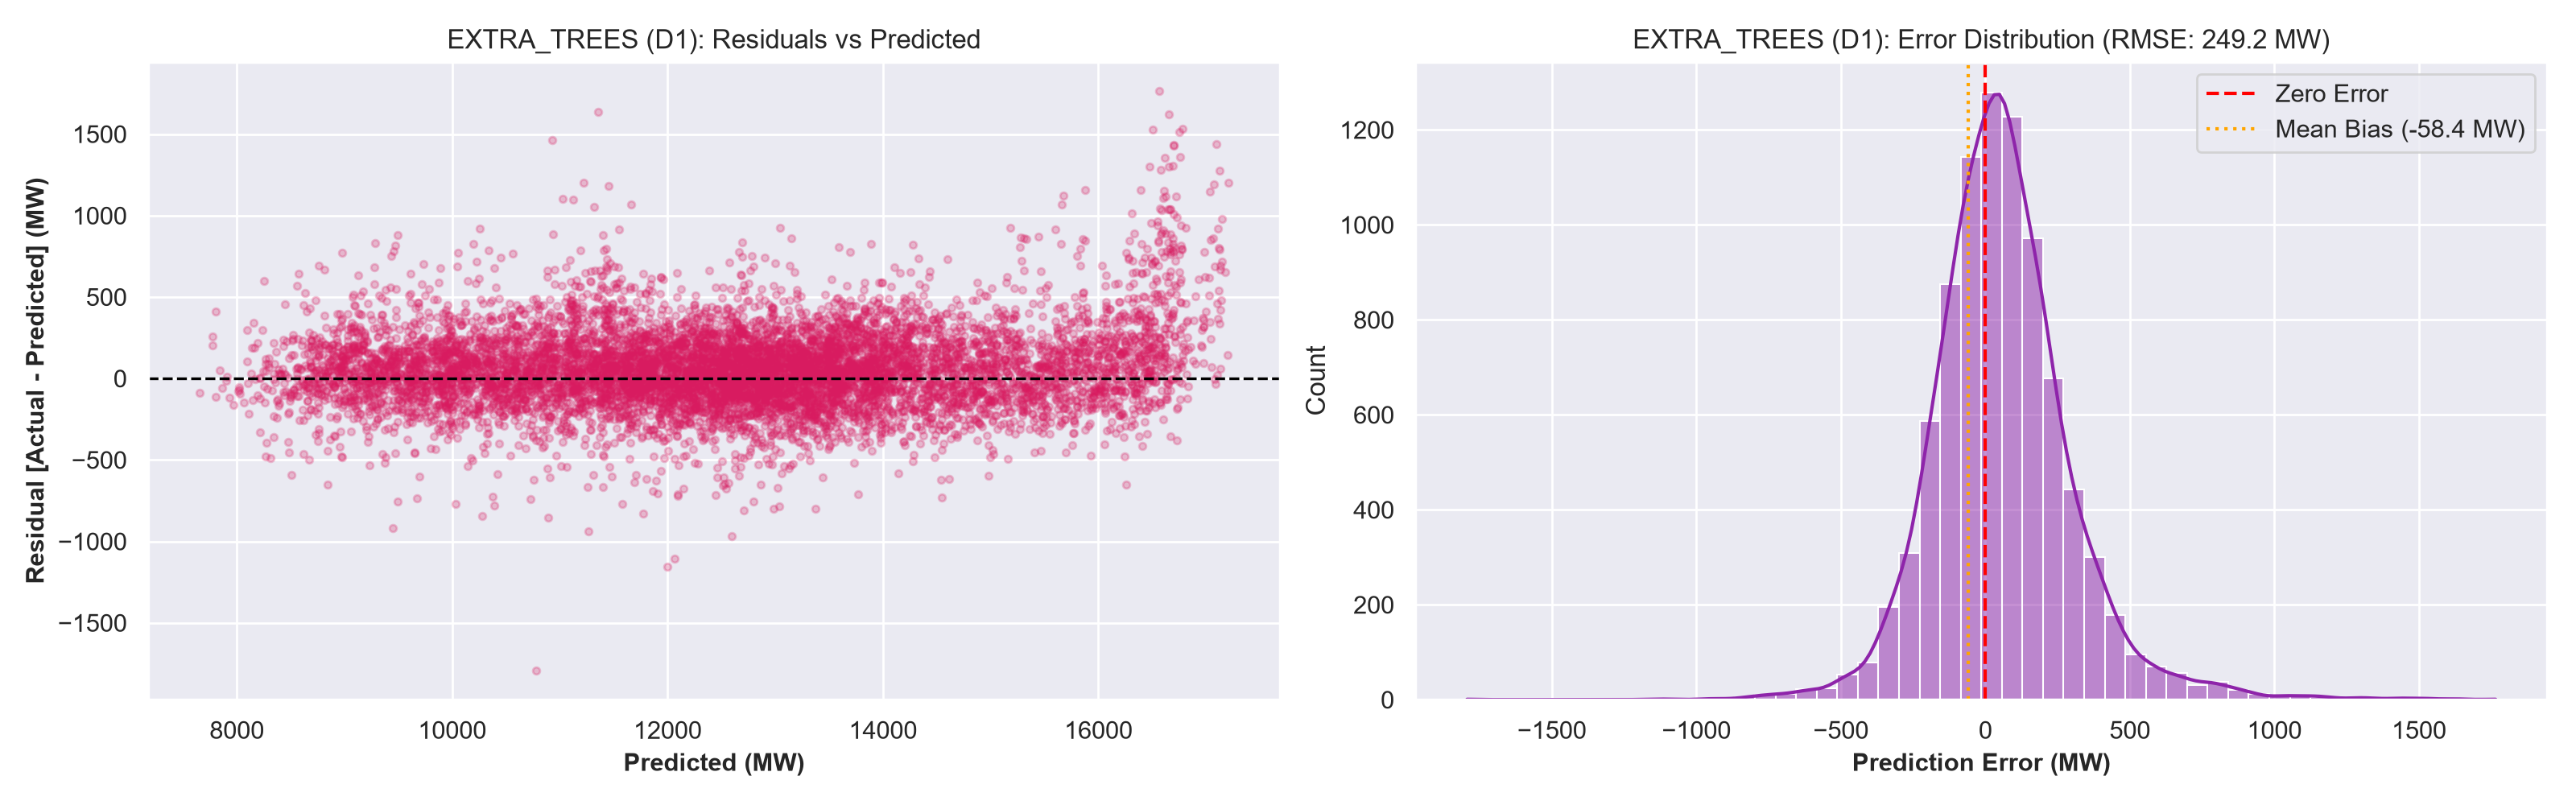

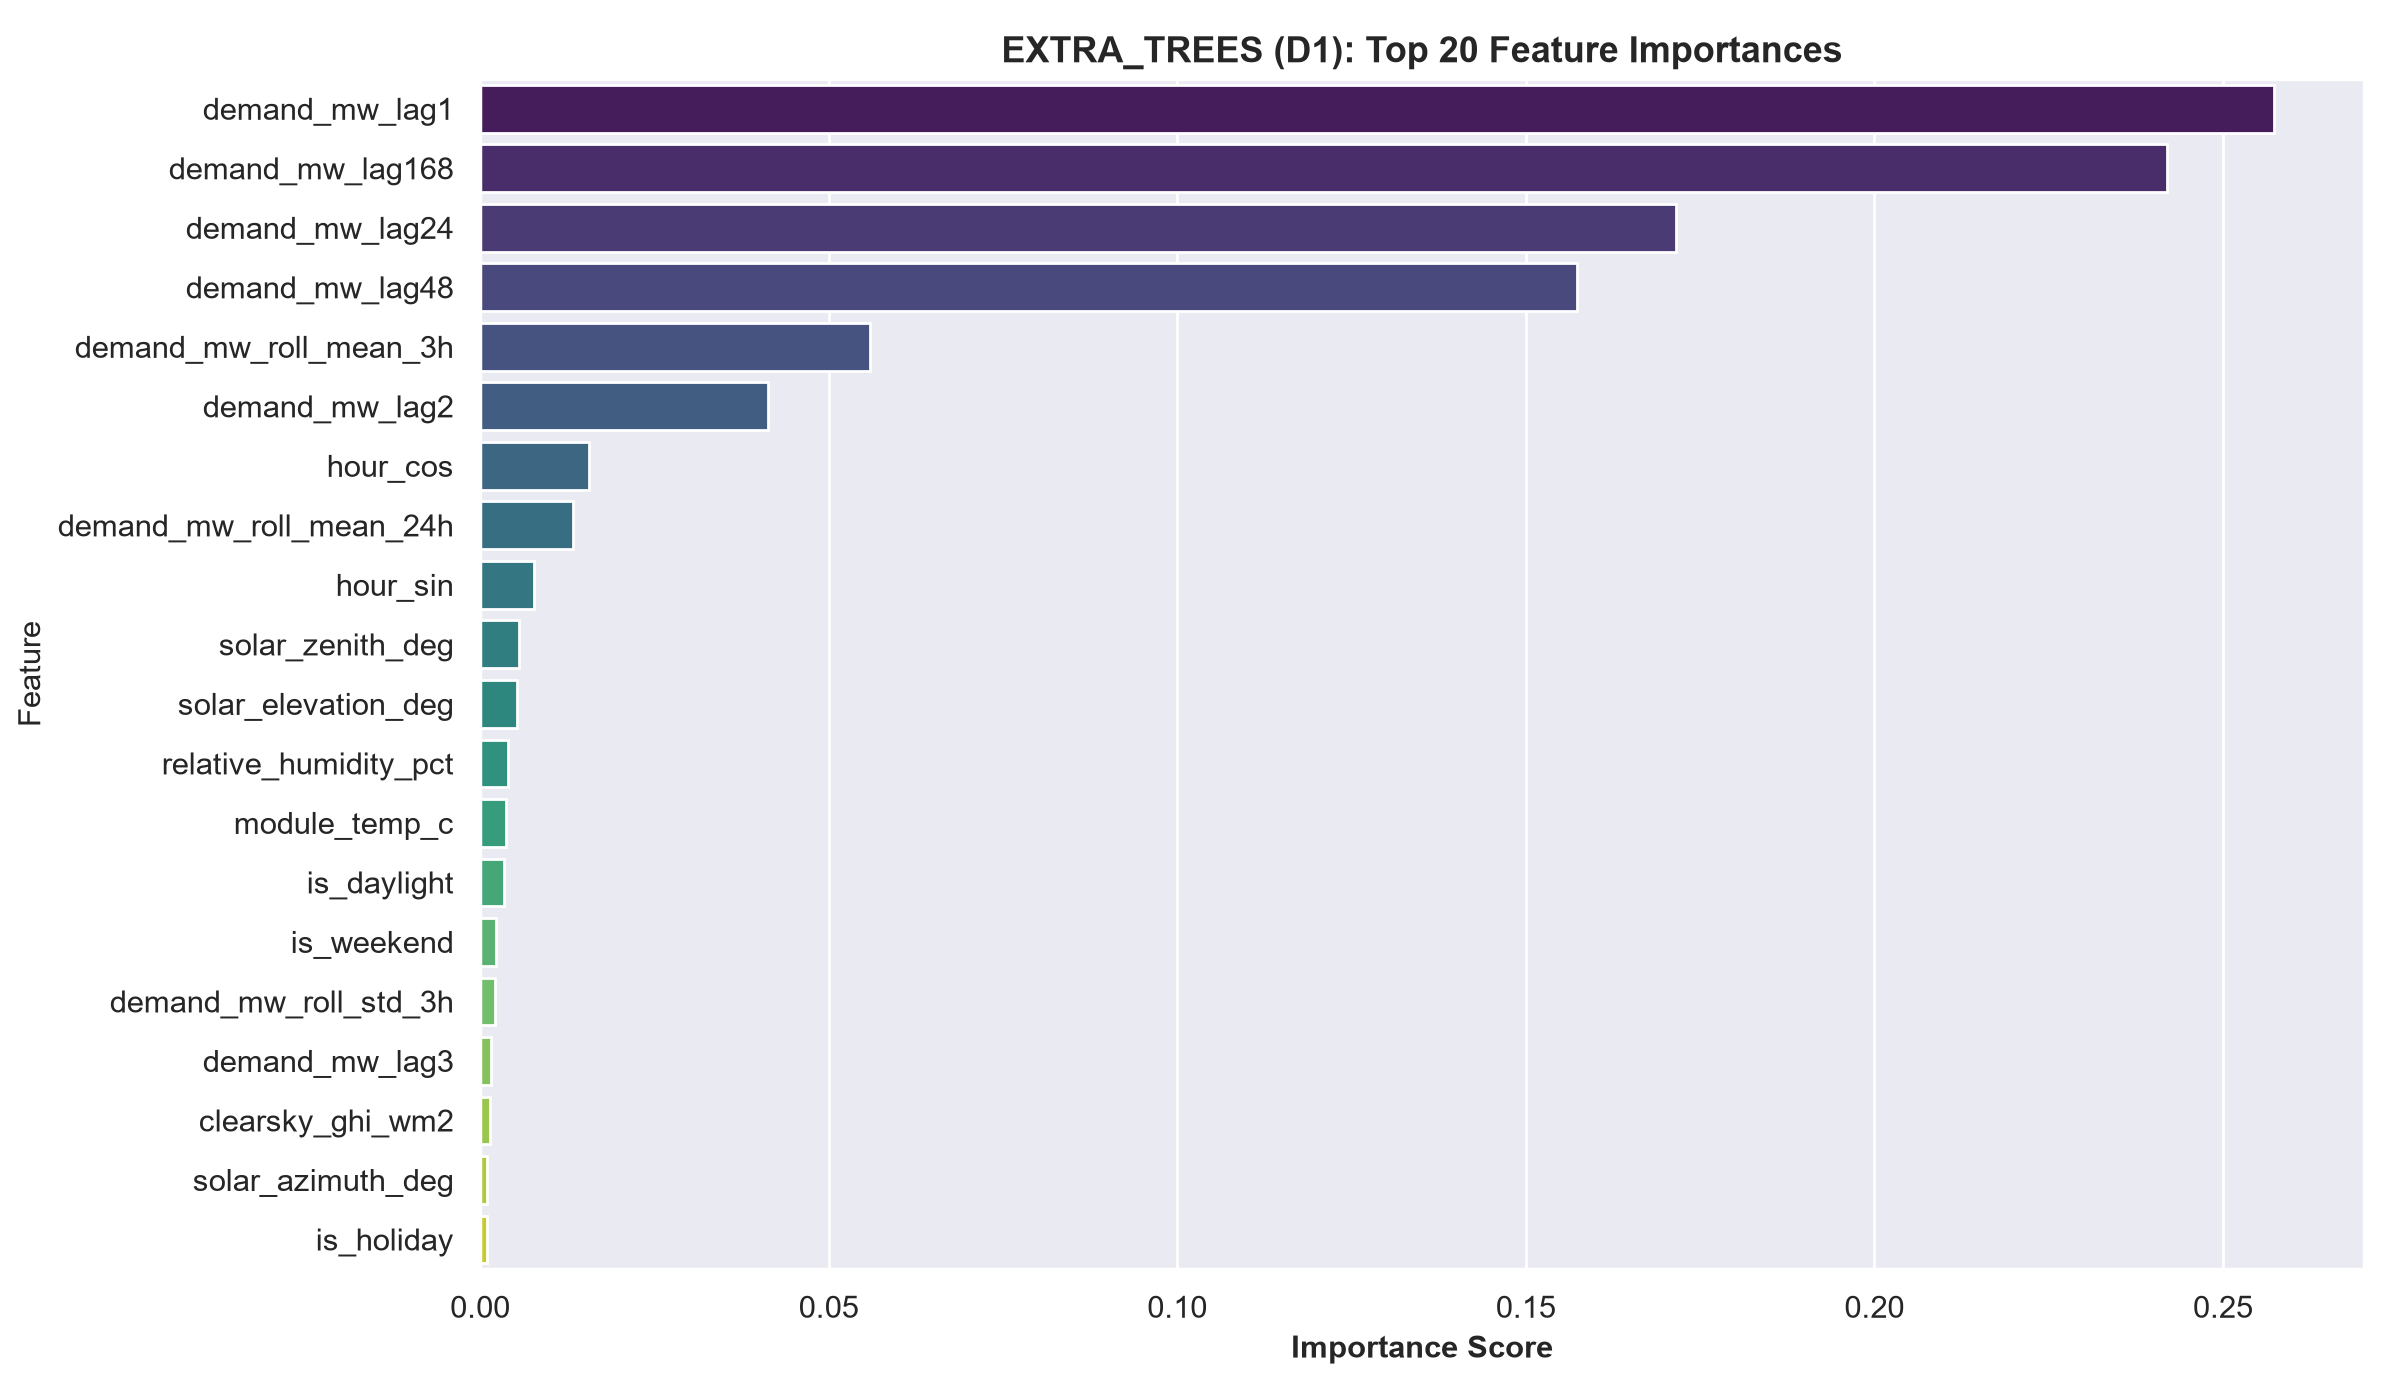


DIAGNOSTIC PLOTS FOR PROBLEM D24


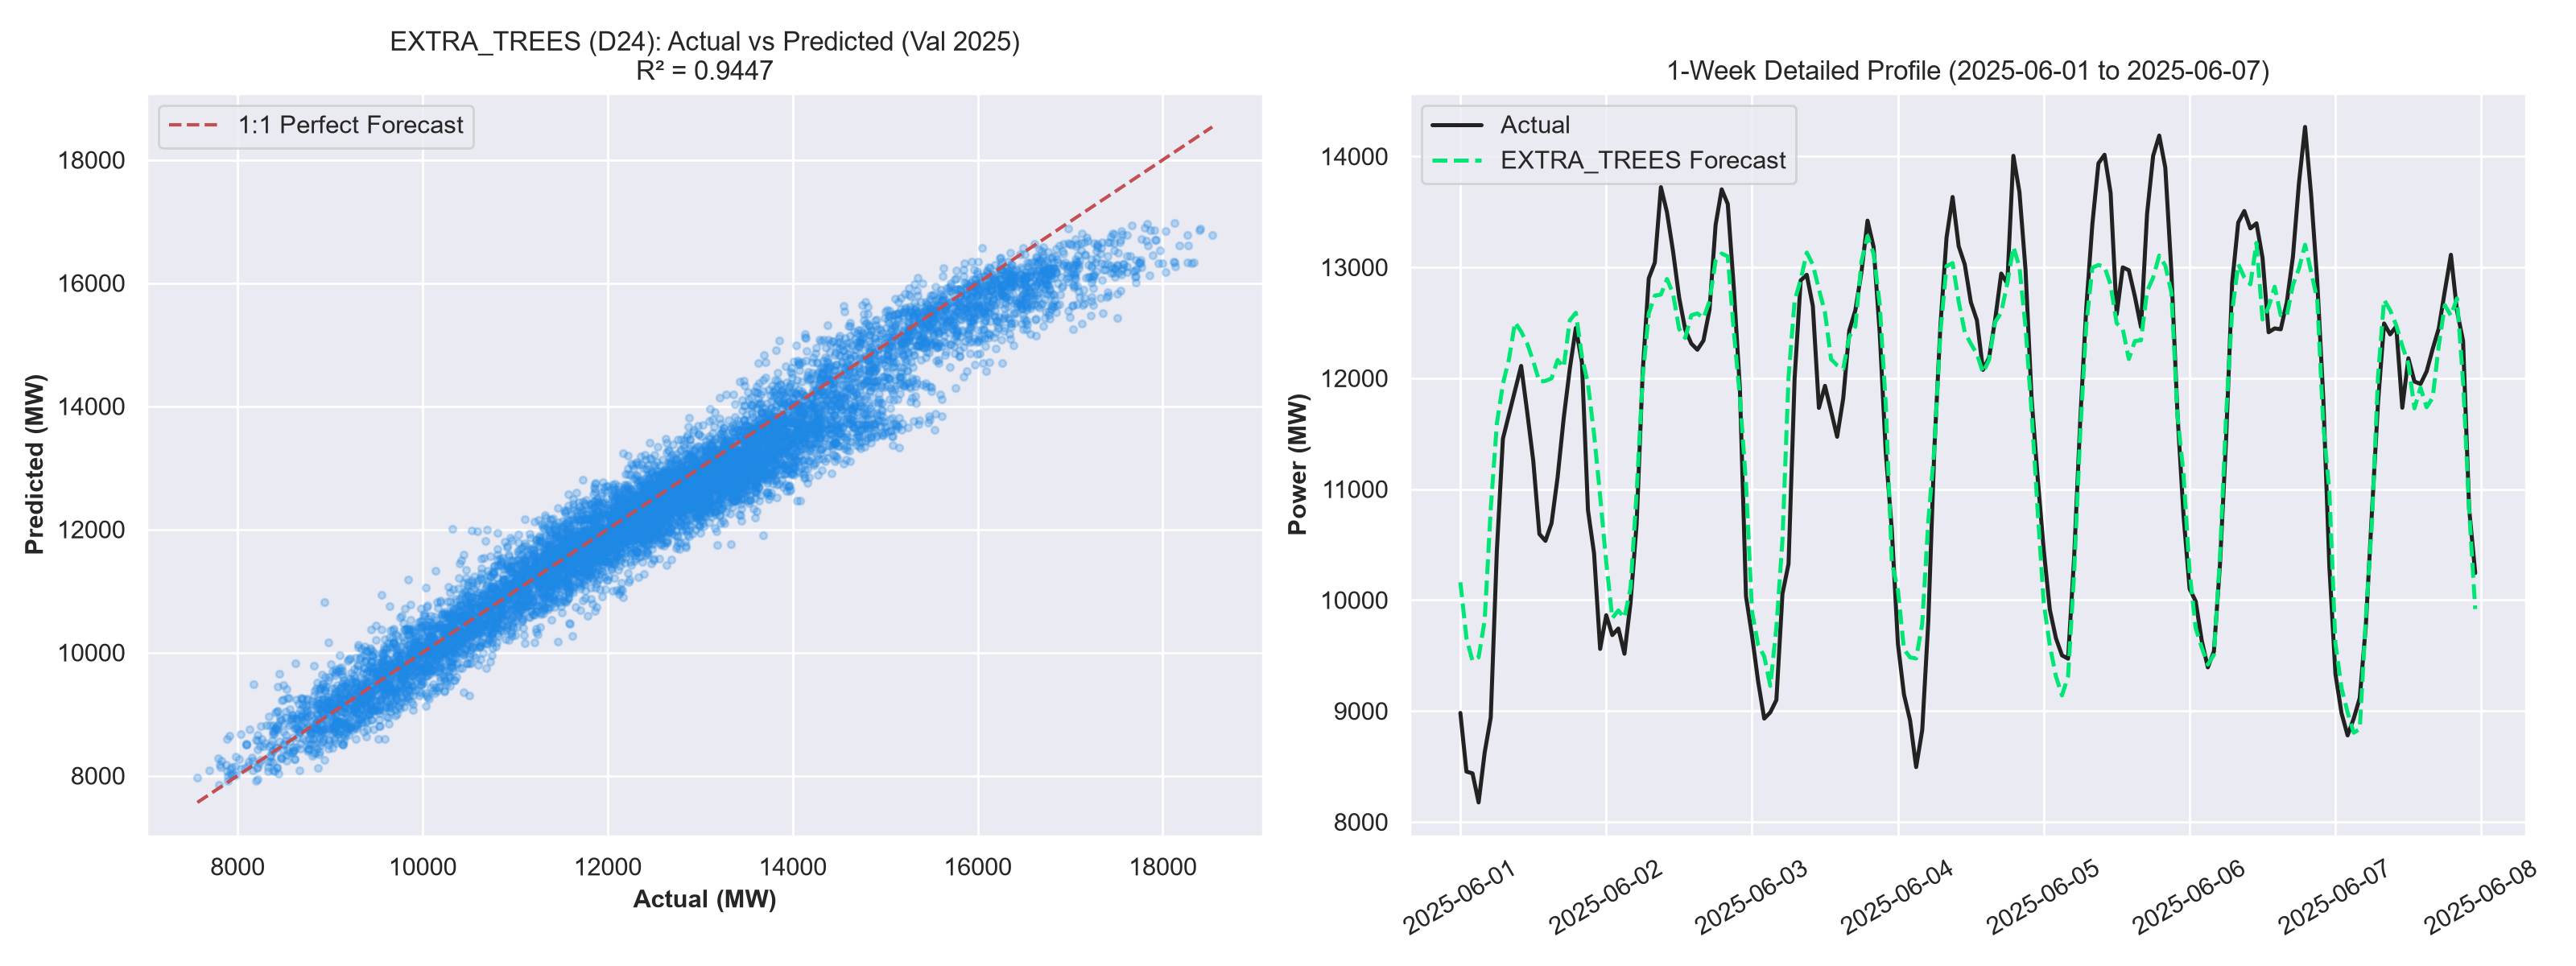

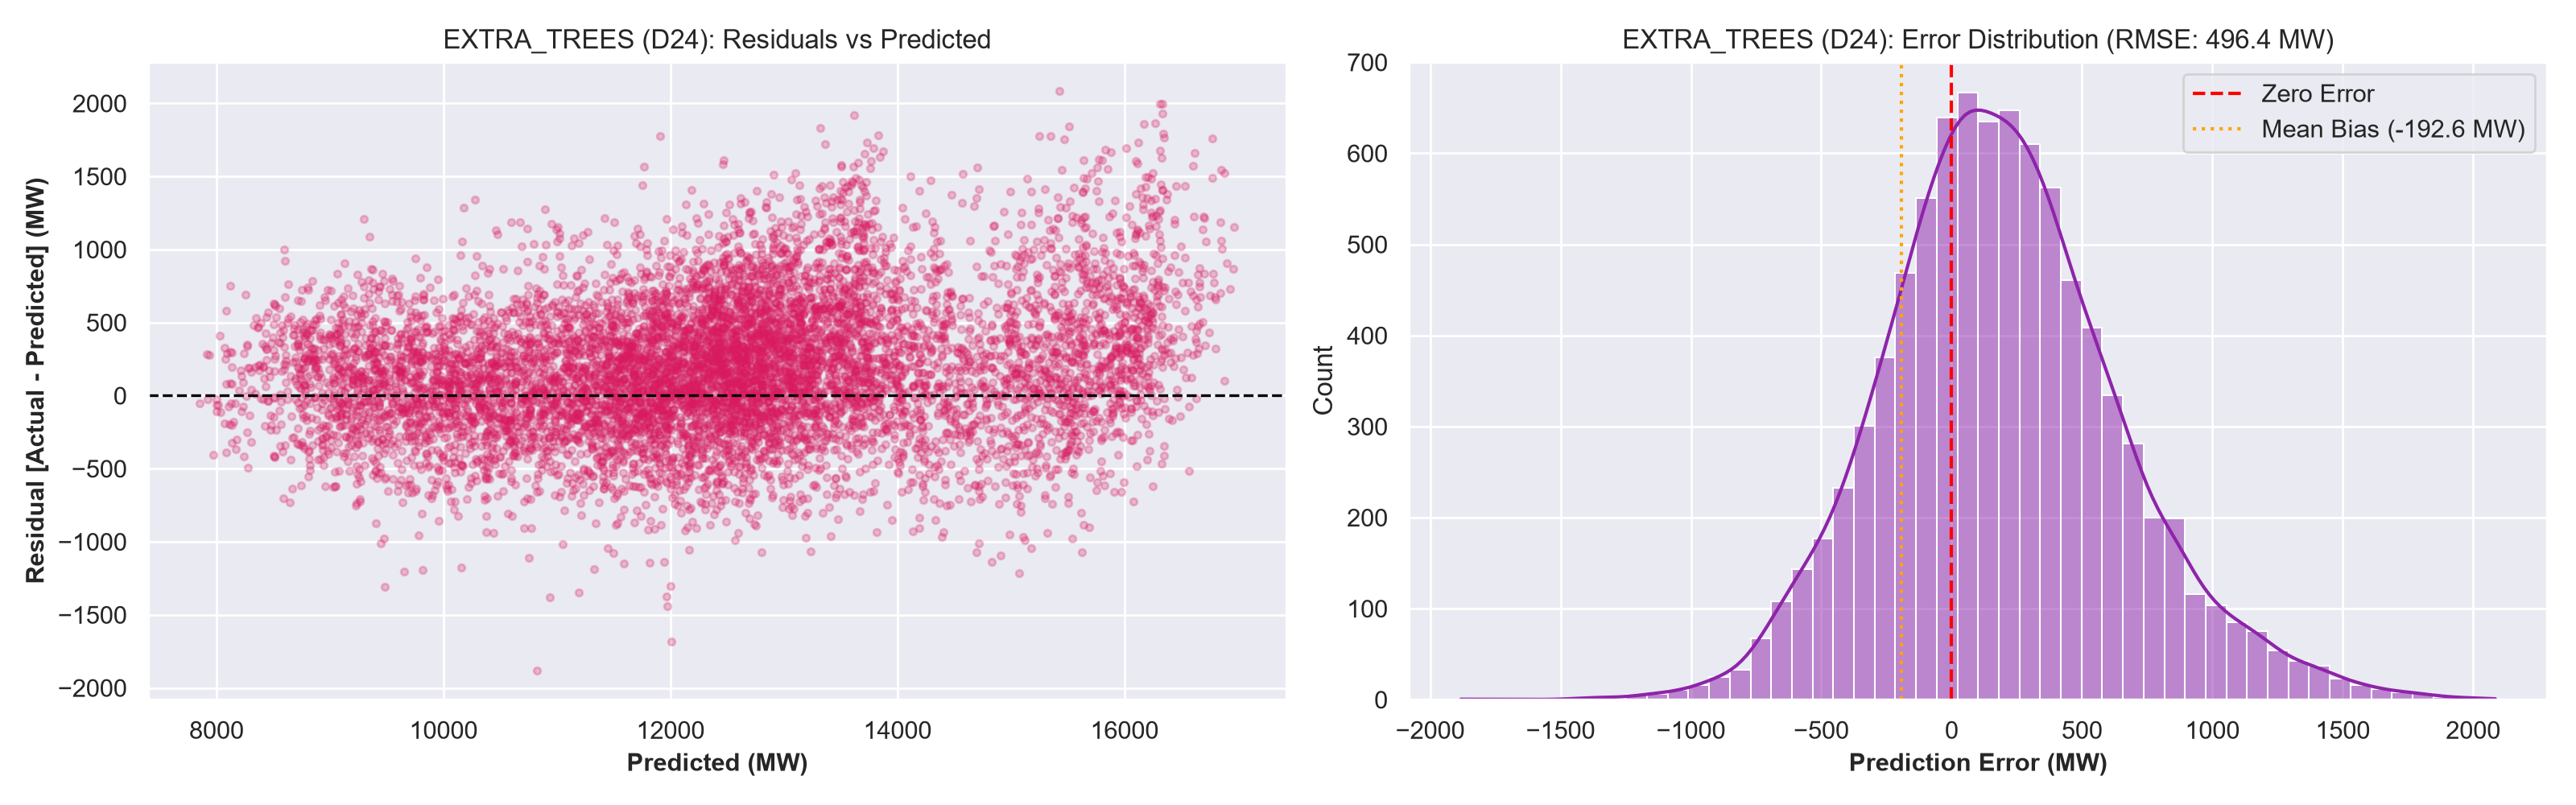

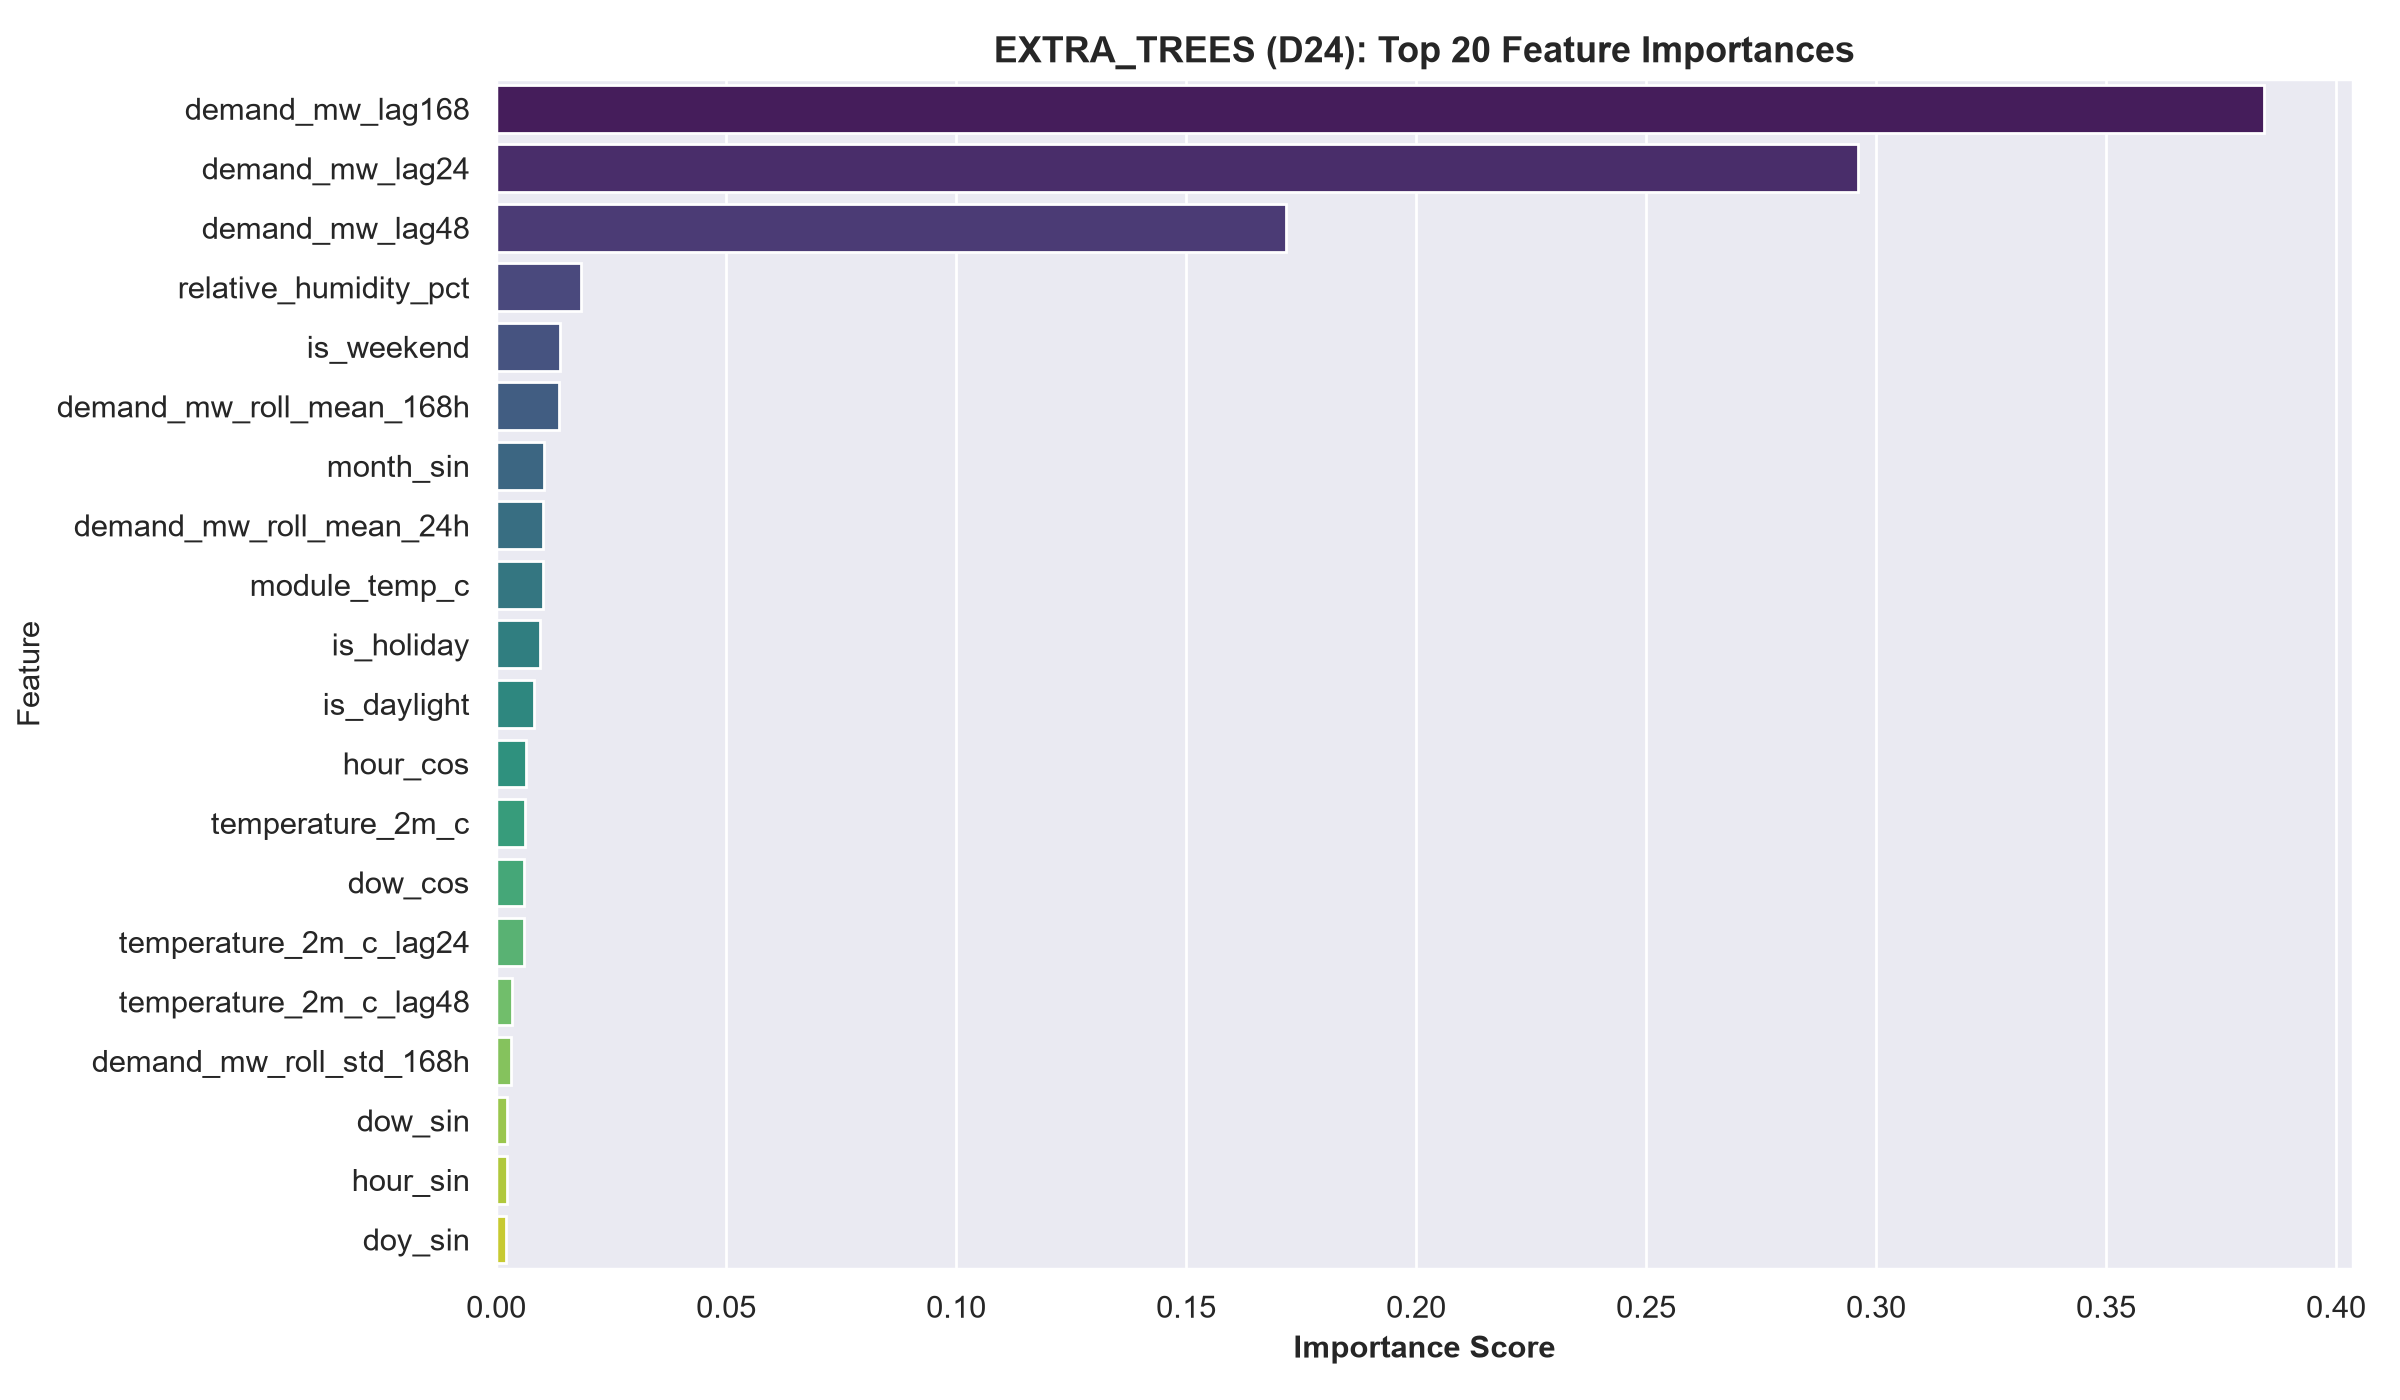

In [4]:
for pid in problems:
    print(f"\n======================================================================\nDIAGNOSTIC PLOTS FOR PROBLEM {pid}\n======================================================================")
    fig_actual = config.FIGURES_CLASSIC_ML_DIR / f"extra_trees_{pid}_actual_vs_predicted.png"
    fig_resid = config.FIGURES_CLASSIC_ML_DIR / f"extra_trees_{pid}_residuals_distribution.png"
    fig_imp = config.FIGURES_CLASSIC_ML_DIR / f"extra_trees_{pid}_feature_importance.png"
    
    if fig_actual.exists():
        display(Image(filename=str(fig_actual)))
    if fig_resid.exists():
        display(Image(filename=str(fig_resid)))
    if fig_imp.exists():
        display(Image(filename=str(fig_imp)))


## 4. Key Takeaways & Physics Interpretations
1. **Non-linear Learning Capacity**:
   - Complex gradient boosted trees capture subtle non-linear interactions (e.g. Plane-of-Array irradiance combined with module temperature and solar zenith) without requiring manual interaction polynomial expansion.
2. **Persistence & Baseline Comparison**:
   - Compare the Skill Score column against the Milestone M5 baseline floor (0.0%). Substantial positive skill scores validate the predictive value of decision-tree ensembles.
